In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import sys
import os
os.getcwd()
sys.path.append('/home/donglaiyang/Documents/Georgia-Tech/Research/petermann-basin-thermal-model/')

%reload_ext autoreload
%autoreload 2
from src.lowRankGPPrior import lowRankGPPrior

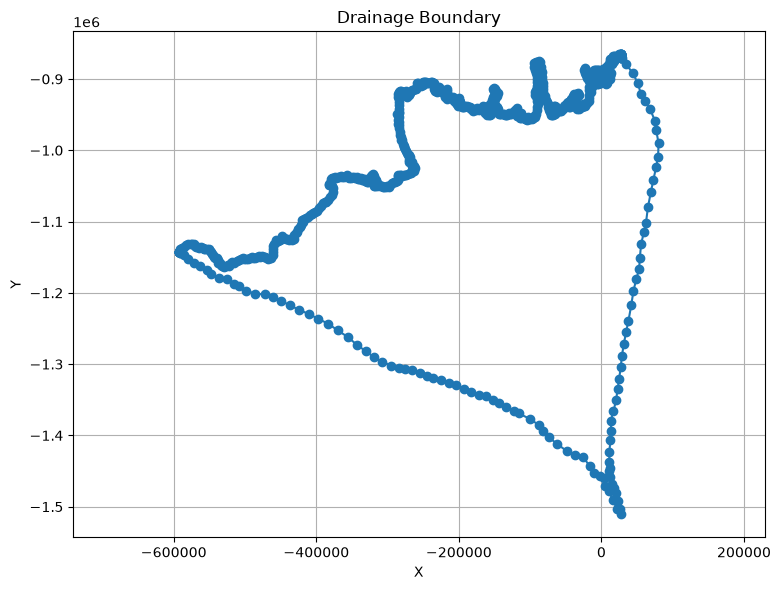

In [25]:
home_dir = '/home/donglaiyang/Documents/Georgia-Tech/Research/petermann-basin-thermal-model'
# first load the domain .exp file
exp_path = f'{home_dir}/data/drainage-boundary/1.1-1.2-downsample-boundary.exp'

with open(exp_path, 'r') as f:
    # load from line 6 to the second last line
    # with space separation
    exp_lines = [[float(x) for x in line.strip().split()] for line in f.readlines()[5:-1]]

vertices = np.array(exp_lines)

plt.figure(figsize=(8, 6))
plt.plot(vertices[:, 0], vertices[:, 1], 'o-')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Drainage Boundary')
plt.grid(True)
plt.tight_layout()
# equal axis
plt.axis('equal')
plt.show()



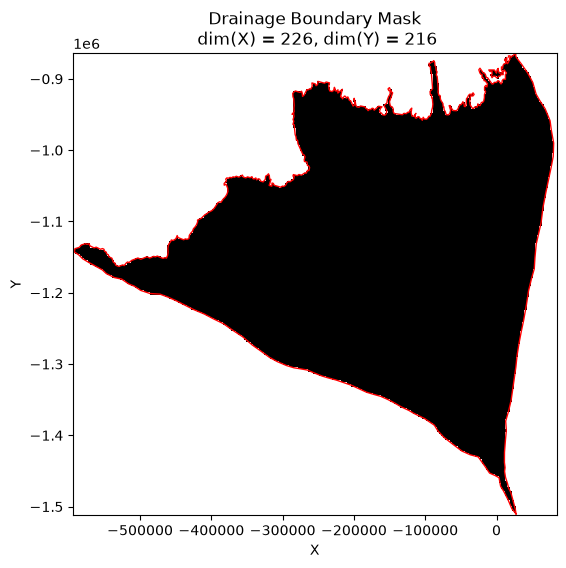

In [26]:
from matplotlib.path import Path

# Grid spacing in the same units as vertices (meters for EPSG:3413)
dx = 3000
dy = 3000

# Build the grid
x = np.arange(vertices[:, 0].min(), vertices[:, 0].max() + dx, dx)
y = np.arange(vertices[:, 1].min(), vertices[:, 1].max() + dy, dy)
X, Y = np.meshgrid(x, y)

# Test grid points against the polygon
polygon = Path(vertices)
points = np.column_stack((X.ravel(), Y.ravel()))

mask = polygon.contains_points(points).reshape(X.shape).astype(np.uint8)

# Plot the binary mask and original boundary
fig, ax = plt.subplots(figsize=(8, 6))
ax.pcolormesh(X, Y, mask, shading='nearest',
              cmap='gray_r', vmin=0, vmax=1)

# Close the outline for plotting
outline = np.vstack((vertices, vertices[0]))
ax.plot(outline[:, 0], outline[:, 1], 'r-', linewidth=1)

ax.set_aspect('equal')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title(f'Drainage Boundary Mask\n dim(X) = {X.shape[1]}, dim(Y) = {Y.shape[0]}')
plt.show()


Step 1: Eigen-decomposition on graph Laplacian...
...Done.
Step 2: Get mode covariance under Matern kernel...
...Done.
Step 3: scale the basis with variance...


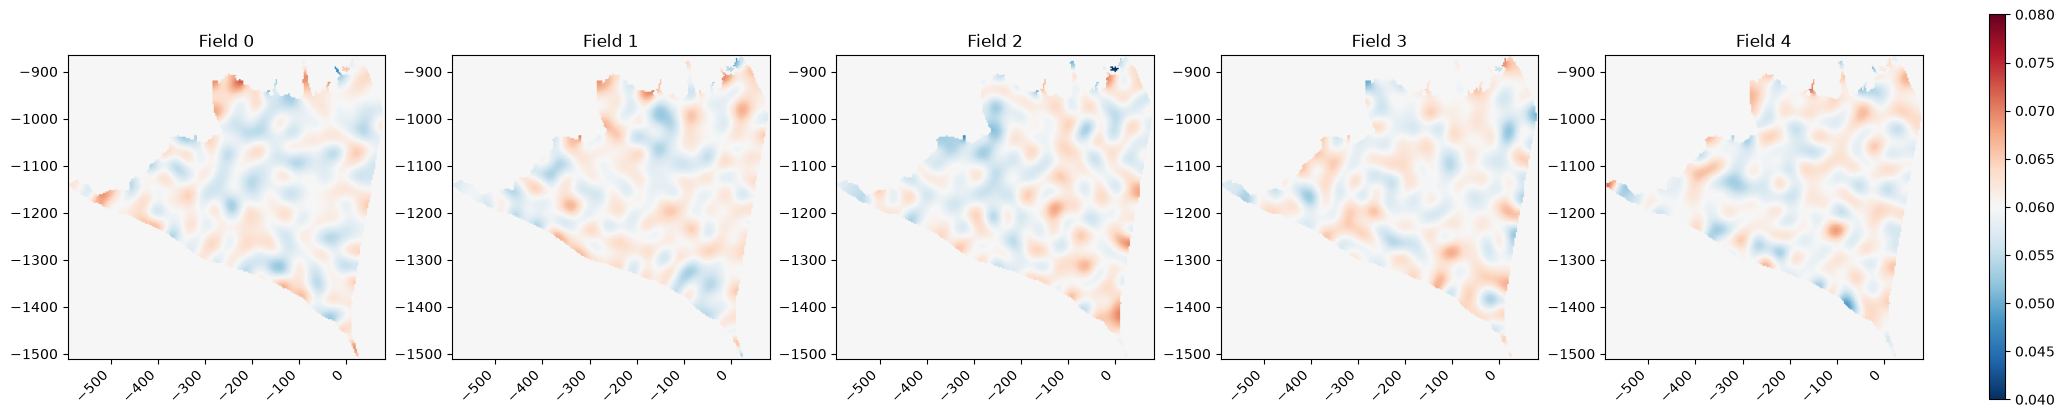

In [81]:
GP_model = lowRankGPPrior(
    domain_mask = mask,
    x = x,
    y = y,
    n_mode = 300,
    sigma_amp = 0.05,
    nu = 0.5,
    rho = 30e3
)
GP_model.basis()

# make 5 fields for visualization
fields = GP_model.generate_random_field(5)
mean = 0.06
fields += mean

GP_model.plot_random_fields(fields, vmin=-0.02 + mean, vmax=0.02 + mean)

### Generate random fields for ISSM modeling

In [ ]:
n_fields = 500
mean = 0.06
fields = GP_model.generate_random_field(n_fields)
fields += mean

fields = fields.reshape(
    GP_model.ny, 
    GP_model.nx,
    n_fields
)
fields[mask==0, :] = np.nan


# save to .mat
import scipy.io as sio
GHF = {"fields": fields, "x": x, "y": y}
sio.savemat(home_dir + "/data/GHF/GHF_random_fields.mat", GHF)